# NinjaTrader 8 EOD data in Python – quick start

Load the plain-text files written by the free **WealthMetaStockToNT8 Converter** (or any NinjaTrader 8 end-of-day file) into pandas, check them, chart them and export them.

This notebook uses the **made-up sample data** in `../sample_data` – change `DATA` to your own converter output folder.

> ⚠ **Important:** For education and analysis only – not investment advice. The toolkit does not provide market data. Always compare converted data with your original files.

In [1]:
import sys; sys.path.insert(0, "../python")
import pandas as pd
import matplotlib.pyplot as plt
import wt_nt8_eod as wt

DATA = "../sample_data"          # <- your converter output folder, e.g. r"C:\NT8 out"
df = wt.read_output(DATA)        # reads its NT-All folder: every symbol once
df.head()

,symbol,date,open,high,low,close,volume,folder
0,ALPHA,2022-01-03,120.86,121.54,120.51,120.63,113201,.
1,ALPHA,2022-01-04,121.07,121.53,118.20,118.69,195800,.
2,ALPHA,2022-01-05,118.70,121.01,117.63,120.17,227341,.
3,ALPHA,2022-01-06,120.29,122.16,119.75,122.04,116443,.
4,ALPHA,2022-01-07,122.07,122.60,117.88,118.34,167027,.


## One row per symbol

## The converter's own lists
`Symbol-Mapping.txt` (original=mapped) and the NT8 symbol import lists.

In [2]:
mapping = wt.read_symbol_mapping(f"{DATA}/Symbol-Mapping.txt")
symbols = wt.read_import_list(f"{DATA}/NT8-All Symbol-Import-List.txt")
print(len(mapping), "mappings;", len(symbols), "symbols:", symbols)

7 mappings; 7 symbols: ['ALPHA', 'BRAVO', 'CHARLIE', 'DEMOINDEX', 'NOVA', 'ORBIT', 'ZENITH']


In [3]:
wt.summary(df)

,first_date,last_date,bars,last_close
symbol,,,,
ALPHA,2022-01-03,2024-12-31,782,110.47
BRAVO,2022-01-03,2024-12-31,782,58.25
CHARLIE,2022-01-03,2024-12-31,782,1745.11
DEMOINDEX,2022-01-03,2024-12-31,782,30166.81
NOVA,2022-01-03,2024-12-31,782,225.64
ORBIT,2022-01-03,2024-12-31,782,34.97
ZENITH,2022-01-03,2024-12-31,782,9254.15


## Data-quality check
Duplicate dates, high < low, bad prices, long gaps and big one-day moves (often an unadjusted split or bonus).

In [4]:
report = wt.check_quality(df)
report if not report.empty else "No issues found" 

'No issues found'

## Closes side by side, rebased to 100

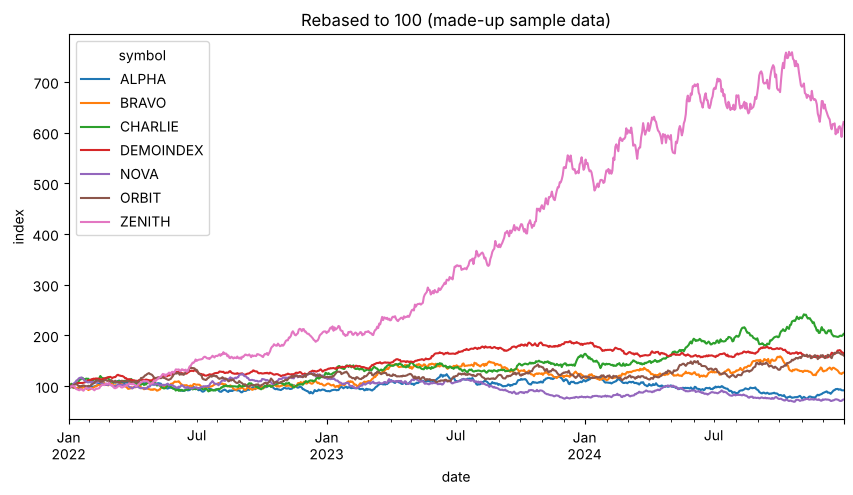

In [5]:
close = wt.to_wide(df, "close")
(close / close.iloc[0] * 100).plot(figsize=(10, 5), title="Rebased to 100 (made-up sample data)")
plt.ylabel("index"); plt.show()

## Simple indicators: 50- and 200-day moving averages

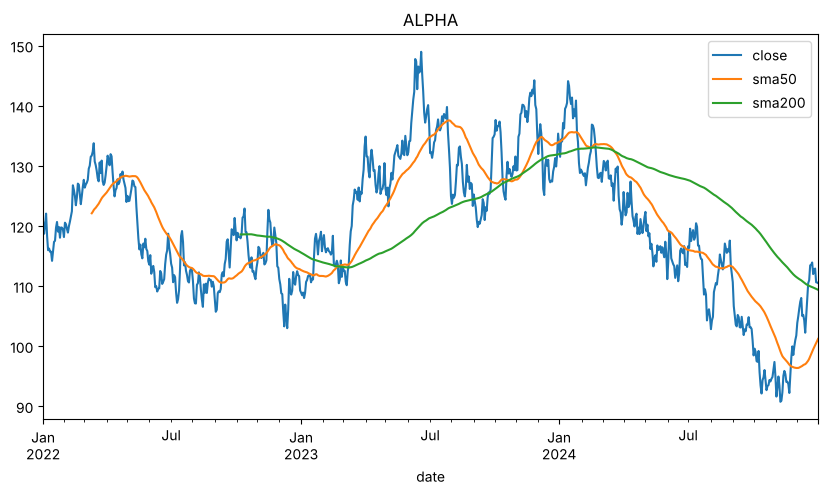

In [6]:
sym = close.columns[0]
s = close[sym]
pd.DataFrame({"close": s, "sma50": s.rolling(50).mean(), "sma200": s.rolling(200).mean()}).plot(figsize=(10, 5), title=sym)
plt.show()

## Export for Excel or other tools

In [7]:
wt.export(df, "all_data.csv")            # long format: symbol, date, open, high, low, close, volume
close.to_csv("closes_wide.csv")           # one close column per symbol
print("saved")

saved
